# Credit Risk Assessment for Loan Default Prediction: research notebook

This notebook contains the full research behind the term paper: data exploration, feature building,
six experiments (baseline reproduction, feature selection, model comparison, validation, SHAP, stress tests)
and the files used by the web application. Every figure and table of the report is produced here.

**Contents**

0. Setup and run options
1. Data and exploratory analysis
2. Feature building
3. Experiment 1: reproduction of the baseline
4. Experiment 2: feature engineering and selection
5. Experiment 3: model comparison
6. Experiment 4: out-of-time validation, calibration and master scale
7. Experiment 5: model interpretation with SHAP
8. Experiment 6: stress testing
9. Files for the web application
10. Summary of key results

**Data.** The raw files go in `data/` (`data/train_data/train_data_{0..11}.pq` and `data/train_target.csv`).
Applications are numbered in time order, so the split is by application id:
train = partitions 0-7 (ids 0-1,999,999), validation = 8-9, out-of-time (OOT) test = 10-11.

**Run options.** Training all models takes several hours and CatBoost needs a GPU. With `RETRAIN = False`
the notebook loads the trained models from `artifacts/models/` and recomputes every result from them;
with `RETRAIN = True` it trains everything from scratch.

## 0. Setup and run options

In [1]:
import gc
import json
import sys
import textwrap
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import lightgbm as lgb
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from catboost import CatBoostClassifier, Pool
from scipy.optimize import brentq
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from pd_scoring import plotstyle as ps
from pd_scoring.config import (FEATURES_DIR, FIGURES_DIR, MODELS_DIR, N_PARTS, RESULTS_DIR, SPEC_PATH,
                               TARGET_PATH, raw_part_path)
from pd_scoring.data import (OOT_PARTS, TRAIN_PARTS, VALID_PARTS, ArraySequence, all_feature_columns, load,
                             load_frame)
from pd_scoring.features import PAYM_COLS, SHIFTED_PAYM, FeatureSpec, baseline_feature_names, build_features
from pd_scoring.labels import describe
from pd_scoring.metrics import binomial_test_grades, hosmer_lemeshow, psi, summary
from pd_scoring.risk import (GRADE_NAMES, LGD_BASE, LGD_DOWNTURN, estimate_rho_from_default_rates, grade,
                             irb_capital, vasicek_conditional_pd)

import matplotlib.pyplot as plt
import shap
from matplotlib.patches import FancyBboxPatch

%matplotlib inline
ps.apply()
pd.set_option("display.width", 160)

RETRAIN = False             # True: train all models again (hours, CatBoost on GPU)
BUILD_FEATURES = not all((FEATURES_DIR / f"part_{i:02d}.parquet").exists() for i in range(N_PARTS))
UPDATE_APP_ASSETS = False   # True: rewrite the sample portfolio and defaults used by the app
TAKE_SCREENSHOTS = False    # True: capture app screenshots (needs Chrome and a running app)
FINAL = "cb_d8_lr06_bern"   # final CatBoost configuration (best validation AUC in Experiment 3)
K = 200                     # number of selected features


def show(fig, name):
    # save a figure for the report and show it in the notebook
    fig.savefig(FIGURES_DIR / name)
    plt.show()


def write_json(obj, name):
    with open(RESULTS_DIR / name, "w") as f:
        json.dump(obj, f, indent=2, default=float)


def read_json(name):
    with open(RESULTS_DIR / name) as f:
        return json.load(f)


def cached_predictions(name, predict):
    # predictions of a trained model on the validation and OOT samples, cached in artifacts/models
    pv, pt = MODELS_DIR / f"pred_valid_{name}.npy", MODELS_DIR / f"pred_oot_{name}.npy"
    if not (pv.exists() and pt.exists()):
        p_va, p_te = predict()
        np.save(pv, p_va)
        np.save(pt, p_te)
    return np.load(pv), np.load(pt)


print("RETRAIN =", RETRAIN, "| BUILD_FEATURES =", BUILD_FEATURES)

C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RETRAIN = False | BUILD_FEATURES = False


## 1. Data and exploratory analysis

Each row of the raw data is one credit product in an applicant's bureau history, so an applicant has
several rows. All fields except the ids are already binned and coded. The analysis below uses partition 5
(250,000 applications) and looks at the length of the credit history, the monthly payment statuses and
whether the bin codes are ordered by risk.

In [2]:
tgt = pd.read_csv(TARGET_PATH)
tgt["part"] = tgt.id // 250_000
print("applications:", len(tgt), "| default rate:", round(tgt.flag.mean(), 4))

loans = pq.read_table(raw_part_path(5)).to_pandas().merge(tgt[["id", "flag"]], on="id")
stats = {"rows_part5": len(loans), "apps_part5": int(loans.id.nunique())}
print("partition 5:", stats)
loans.head()

applications: 3000000 | default rate: 0.0355


partition 5: {'rows_part5': 2150908, 'apps_part5': 250000}


,id,rn,pre_since_opened,pre_since_confirmed,pre_pterm,pre_fterm,pre_till_pclose,pre_till_fclose,pre_loans_credit_limit,pre_loans_next_pay_summ,...,enc_paym_22,enc_paym_23,enc_paym_24,enc_loans_account_holder_type,enc_loans_credit_status,enc_loans_credit_type,enc_loans_account_cur,pclose_flag,fclose_flag,flag
0,1250000,1,17,3,15,12,11,0,16,2,...,3,3,4,1,3,4,1,0,0,0
1,1250000,2,9,10,14,7,10,4,15,5,...,3,3,4,1,2,4,1,0,0,0
2,1250001,1,16,5,8,6,4,9,18,2,...,3,3,4,1,2,4,1,0,0,1
3,1250001,2,18,5,16,16,5,6,6,2,...,0,3,4,1,3,4,1,0,0,1
4,1250001,3,5,12,16,8,11,11,3,6,...,3,3,4,1,3,4,1,0,1,1


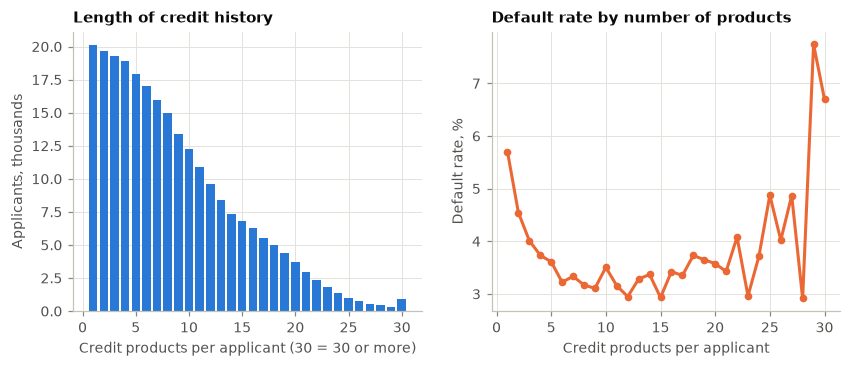

In [3]:
# loans per applicant and default rate by number of products
n = loans.groupby("id").agg(n=("rn", "size"), flag=("flag", "first"))
stats["loans_per_app"] = n.n.describe().to_dict()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
vc = n.n.clip(upper=30).value_counts().sort_index()
axes[0].bar(vc.index, vc.values / 1000, color=ps.SERIES[0], width=0.8)
axes[0].set_xlabel("Credit products per applicant (30 = 30 or more)")
axes[0].set_ylabel("Applicants, thousands")
axes[0].set_title("Length of credit history")
dr = n.assign(nb=n.n.clip(upper=30)).groupby("nb").flag.mean() * 100
axes[1].plot(dr.index, dr.values, marker="o", ms=4, color=ps.SERIES[1])
axes[1].set_xlabel("Credit products per applicant")
axes[1].set_ylabel("Default rate, %")
axes[1].set_title("Default rate by number of products")
show(fig, "eda_products.png")

Payment statuses: 0 = on time, 1 = late, 2 = seriously late, 3 = no data or closed. In months 11, 20 and 24
the codes are stored with a +1 offset (1 = on time ... 4 = no data), so they are shifted back before use.

max code by month: [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 3, 3, 4]


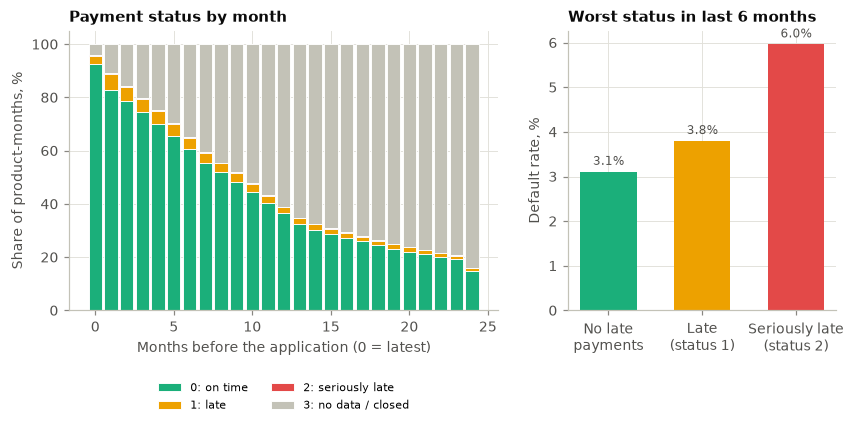

In [4]:
paym = loans[PAYM_COLS].to_numpy().copy()
print("max code by month:", paym.max(0).tolist())
paym[:, SHIFTED_PAYM] = np.clip(paym[:, SHIFTED_PAYM] - 1, 0, 3)
shares = np.stack([(paym == s).mean(0) for s in range(4)])
stats["paym_share_month0"] = shares[:, 0].tolist()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), gridspec_kw={"width_ratios": [1.6, 1]})
bottom = np.zeros(25)
labels = ["0: on time", "1: late", "2: seriously late", "3: no data / closed"]
colors = [ps.SERIES[2], ps.SERIES[3], ps.SERIES[7], "#c3c2b7"]
for s in range(4):
    axes[0].bar(range(25), shares[s] * 100, bottom=bottom, color=colors[s], label=labels[s],
                width=0.85, edgecolor="white", linewidth=0.6)
    bottom += shares[s] * 100
axes[0].set_xlabel("Months before the application (0 = latest)")
axes[0].set_ylabel("Share of product-months, %")
axes[0].set_title("Payment status by month")
axes[0].legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=7.5)
worst = pd.Series(np.where((paym[:, :6] == 2).any(1), 2, np.where((paym[:, :6] == 1).any(1), 1, 0)))
app_worst = worst.groupby(loans.id.values).max()
d2 = pd.DataFrame({"w": app_worst.values, "flag": n.flag.reindex(app_worst.index).values})
g = d2.groupby("w").flag.agg(["mean", "size"])
stats["dr_by_worst6"] = {int(k): [float(v["mean"]), int(v["size"])] for k, v in g.iterrows()}
axes[1].bar(["No late\npayments", "Late\n(status 1)", "Seriously late\n(status 2)"], g["mean"] * 100,
            color=[ps.SERIES[2], ps.SERIES[3], ps.SERIES[7]], width=0.6)
for i, v in enumerate(g["mean"] * 100):
    axes[1].text(i, v + 0.15, f"{v:.1f}%", ha="center", fontsize=8, color=ps.INK2)
axes[1].set_ylabel("Default rate, %")
axes[1].set_title("Worst status in last 6 months")
show(fig, "eda_payments.png")

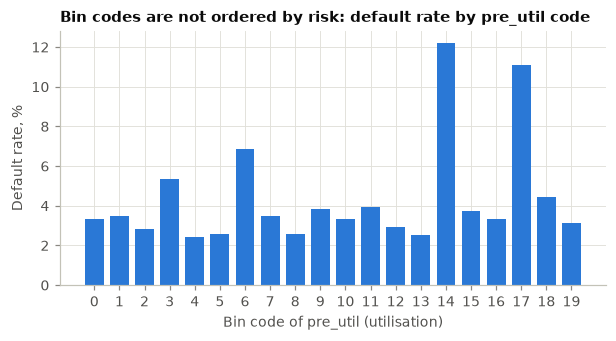

In [5]:
# bin codes are not ordered by risk: default rate by pre_util code
u = loans.groupby("pre_util").flag.agg(["mean", "size"])
stats["pre_util_dr"] = (u["mean"] * 100).round(2).to_dict()
fig, ax = plt.subplots(figsize=(6.4, 3))
ax.bar(u.index, u["mean"] * 100, color=ps.SERIES[0], width=0.75)
ax.set_xticks(u.index)
ax.set_xlabel("Bin code of pre_util (utilisation)")
ax.set_ylabel("Default rate, %")
ax.set_title("Bin codes are not ordered by risk: default rate by pre_util code")
show(fig, "eda_bins.png")
write_json(stats, "eda_stats.json")
del loans, paym, n
gc.collect();

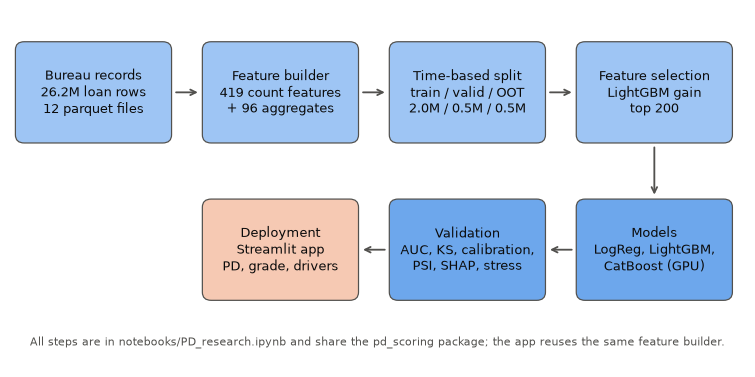

In [ ]:

fig, ax = plt.subplots(figsize=(8.6, 4.2))
ax.set_xlim(0, 100)
ax.set_ylim(0, 52)
ax.axis("off")
steps = [("Bureau records\n26.2M loan rows\n12 parquet files", ps.BLUE_RAMP[1]),
         ("Feature builder\n419 count features\n+ 96 aggregates", ps.BLUE_RAMP[1]),
         ("Time-based split\ntrain / valid / OOT\n2.0M / 0.5M / 0.5M", ps.BLUE_RAMP[1]),
         ("Feature selection\nLightGBM gain\ntop 200", ps.BLUE_RAMP[1]),
         ("Models\nLogReg, LightGBM,\nCatBoost (GPU)", ps.BLUE_RAMP[2]),
         ("Validation\nAUC, KS, calibration,\nPSI, SHAP, stress", ps.BLUE_RAMP[2]),
         ("Deployment\nStreamlit app\nPD, grade, drivers", "#f6c9b3")]
w, h, gap = 20.5, 14, 5.0
pos = [(1 + i * (w + gap), 33) for i in range(4)] + [(1 + (3 - i) * (w + gap), 10) for i in range(3)]
for (txt, col), (x, y) in zip(steps, pos):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.4,rounding_size=1.2",
                                fc=col, ec=ps.INK2, lw=0.8))
    ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=8.5, color=ps.INK)
for i in range(len(steps) - 1):
    (x0, y0), (x1, y1) = pos[i], pos[i + 1]
    if y0 == y1:
        if x1 > x0:
            a, b = (x0 + w + 0.6, y0 + h / 2), (x1 - 0.6, y1 + h / 2)
        else:
            a, b = (x0 - 0.6, y0 + h / 2), (x1 + w + 0.6, y1 + h / 2)
    else:
        a, b = (x0 + w / 2, y0 - 0.6), (x1 + w / 2, y1 + h + 0.6)
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color=ps.INK2, lw=1.2))
ax.text(50, 3, "All steps are in notebooks/PD_research.ipynb and share the pd_scoring package; "
        "the app reuses the same feature builder.", ha="center", fontsize=7.5, color=ps.INK2)
show(fig, "pipeline.png")

## 2. Feature building

A PD model needs one row per application, so the loan-level records are aggregated (`pd_scoring/features.py`):

* `cnt__<field>_<code>`: number of the applicant's products with this code (the one-hot count features of the
  original baseline notebook, 419 columns);
* `agg__`: means and maxima of the bin codes and shares of the flags;
* `pay__`: counts and shares of each payment status over the last 3, 6, 12 and 25 months, and the number of
  months since the latest late payment;
* `last__`: attributes of the most recently opened product.

The list of codes per field is fixed on all partitions first (`feature_spec.json`), so every partition gets the
same columns. The build takes about 15 minutes and is skipped when the feature files already exist.

In [7]:
if BUILD_FEATURES:
    spec = FeatureSpec()
    for i in range(N_PARTS):
        df = pq.read_table(raw_part_path(i)).to_pandas()
        spec.update(df.astype("int16"))
        del df
    spec.save(SPEC_PATH)
    target = pd.read_csv(TARGET_PATH)
    for i in range(N_PARTS):
        t0 = time.time()
        df = pq.read_table(raw_part_path(i)).to_pandas()
        df = df.astype({c: "int32" if c in ("id",) else "int16" for c in df.columns})
        feats = build_features(df, spec)
        del df
        feats = feats.merge(target, on="id", how="left")
        assert feats["flag"].notna().all()
        feats["flag"] = feats["flag"].astype("uint8")
        feats.to_parquet(FEATURES_DIR / f"part_{i:02d}.parquet", index=False)
        print(f"part {i}: {feats.shape} in {time.time() - t0:.0f}s")
        del feats

spec = FeatureSpec.load(SPEC_PATH)
all_cols = all_feature_columns()
base_cols = baseline_feature_names(spec)
groups = pd.Series([c.split("__")[0] for c in all_cols]).value_counts()
print("features:", len(all_cols), "| baseline count features:", len(base_cols))
print(groups.to_string())

features: 515 | baseline count features: 419
cnt     419
agg      49
pay      33
last     14


In [8]:
# labels and ids of the validation and OOT samples, used by all experiments
fva, fte = load_frame(VALID_PARTS, []), load_frame(OOT_PARTS, [])
yva, yte = fva.flag.to_numpy(), fte.flag.to_numpy()
ids_va, ids_te = fva.id.to_numpy(), fte.id.to_numpy()
np.save(MODELS_DIR / "y_valid.npy", yva)
np.save(MODELS_DIR / "y_oot.npy", yte)
np.save(MODELS_DIR / "ids_oot.npy", ids_te)
print("validation:", len(yva), "default rate", yva.mean().round(4), "| OOT:", len(yte), "default rate", yte.mean().round(4))

validation: 500000 default rate 0.0354 | OOT: 500000 default rate 0.0328


## 3. Experiment 1: reproduction of the baseline

The original notebook trained LightGBM on the 419 count features and evaluated it with random cross-validation.
The same features and settings are evaluated here twice: with the time-based split (early stopping on
validation, test on OOT) and with a random 80/20 split of all applications, to show how much a random split
overstates quality.

In [9]:
BASE_PARAMS = {
    "learning_rate": 0.05, "max_depth": 5, "reg_lambda": 1, "objective": "binary",
    "num_leaves": 64, "n_jobs": -1, "metric": "auc", "verbose": -1, "seed": 42,
}

if RETRAIN:
    Xtr, ytr, _ = load(TRAIN_PARTS, base_cols, dtype=np.uint8)
    Xva, _, _ = load(VALID_PARTS, base_cols, dtype=np.uint8)
    Xte, _, _ = load(OOT_PARTS, base_cols, dtype=np.uint8)
    params = dict(BASE_PARAMS, scale_pos_weight=float((ytr == 0).sum() / (ytr == 1).sum()))
    t0 = time.time()
    dtr = lgb.Dataset(ArraySequence(Xtr), label=ytr, feature_name=base_cols, free_raw_data=True)
    dva = lgb.Dataset(ArraySequence(Xva), label=yva, reference=dtr)
    booster = lgb.train(params, dtr, num_boost_round=2000, valid_sets=[dva],
                        callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(100)])
    train_time = time.time() - t0
    p_va = booster.predict(Xva.astype(np.float32), num_iteration=booster.best_iteration)
    p_te = booster.predict(Xte.astype(np.float32), num_iteration=booster.best_iteration)
    booster.save_model(str(MODELS_DIR / "lgb_baseline.txt"), num_iteration=booster.best_iteration)
    np.save(MODELS_DIR / "pred_valid_lgb_baseline.npy", p_va)
    np.save(MODELS_DIR / "pred_oot_lgb_baseline.npy", p_te)
    exp1 = {"model": "LightGBM baseline (count features, original params)", "n_features": len(base_cols),
            "best_iteration": booster.best_iteration, "train_time_s": round(train_time, 1),
            "valid": summary(yva, p_va), "oot": summary(yte, p_te)}
    del dtr, dva

    # the same model under a random 80/20 split of all 3M applications
    X = np.vstack([Xtr, Xva, Xte])
    y = np.concatenate([ytr, yva, yte])
    del Xtr, Xva, Xte
    rng = np.random.default_rng(42)
    perm = rng.permutation(len(y))
    cut = int(0.8 * len(y))
    tr, te = np.sort(perm[:cut]), np.sort(perm[cut:])
    dtr = lgb.Dataset(ArraySequence(X[tr]), label=y[tr], feature_name=base_cols)
    dte = lgb.Dataset(ArraySequence(X[te]), label=y[te], reference=dtr)
    b2 = lgb.train(params, dtr, num_boost_round=2000, valid_sets=[dte],
                   callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(100)])
    p = b2.predict(X[te].astype(np.float32), num_iteration=b2.best_iteration)
    exp1["random_split_auc"] = float(roc_auc_score(y[te], p))
    exp1["random_split_best_iteration"] = b2.best_iteration
    write_json(exp1, "exp1_baseline.json")
    del X, y, dtr, dte
    gc.collect()
else:
    exp1 = read_json("exp1_baseline.json")
    booster = lgb.Booster(model_file=str(MODELS_DIR / "lgb_baseline.txt"))

    def predict_baseline():
        Xva, _, _ = load(VALID_PARTS, base_cols)
        Xte, _, _ = load(OOT_PARTS, base_cols)
        return booster.predict(Xva), booster.predict(Xte)

    p_va, p_te = cached_predictions("lgb_baseline", predict_baseline)
    exp1["valid"], exp1["oot"] = summary(yva, p_va), summary(yte, p_te)

pd.DataFrame({"random 80/20 split": {"auc": exp1["random_split_auc"]},
              "validation (time split)": exp1["valid"], "OOT test (time split)": exp1["oot"]}).T[
    ["auc", "gini", "ks", "mean_pd"]].round(4)

,auc,gini,ks,mean_pd
random 80/20 split,0.7586,NaN,NaN,NaN
validation (time split),0.7494,0.4989,0.3684,0.3812
OOT test (time split),0.7356,0.4712,0.3485,0.3841


The random split gives AUC 0.759, close to the 0.761 cross-validation result of the original notebook, but the
same model reaches only 0.736 on the later OOT applications. The mean predicted PD (about 38%) is far above the
observed default rate (3.3%) because the baseline uses class weighting, so its scores are not probabilities.

## 4. Experiment 2: feature engineering and selection

LightGBM is trained on a 25% sample of the training partitions with (a) the baseline count features only,
(b) the engineered features only and (c) all features. Features are then ranked by total gain and models
on the top-K features are trained to choose how many features to keep.

In [10]:
FS_PARAMS = {"objective": "binary", "learning_rate": 0.05, "num_leaves": 64, "max_depth": -1,
             "min_child_samples": 200, "feature_fraction": 0.5, "bagging_fraction": 0.8,
             "bagging_freq": 1, "reg_lambda": 5, "metric": "auc", "verbose": -1, "seed": 42, "n_jobs": -1}


def fit_eval(Xtr, ytr, Xva, yva, names):
    dtr = lgb.Dataset(Xtr, label=ytr, feature_name=names, free_raw_data=True)
    dva = lgb.Dataset(Xva, label=yva, reference=dtr)
    b = lgb.train(FS_PARAMS, dtr, 3000, valid_sets=[dva], callbacks=[lgb.early_stopping(100, verbose=False)])
    return b, summary(yva, b.predict(Xva, num_iteration=b.best_iteration))


if RETRAIN:
    Xs, ys, _ = load(TRAIN_PARTS, all_cols, sample_frac=0.25, seed=1)
    Xvs, yvs, _ = load(VALID_PARTS, all_cols, sample_frac=0.5, seed=2)
    col_idx = {c: i for i, c in enumerate(all_cols)}
    exp2 = {}
    bi = [col_idx[c] for c in base_cols]
    _, m = fit_eval(Xs[:, bi], ys, Xvs[:, bi], yvs, base_cols)
    exp2["baseline_counts"] = dict(m, n_features=len(base_cols))
    eng = [c for c in all_cols if not c.startswith("cnt__")]
    ei = [col_idx[c] for c in eng]
    _, m = fit_eval(Xs[:, ei], ys, Xvs[:, ei], yvs, eng)
    exp2["engineered_only"] = dict(m, n_features=len(eng))
    b, m = fit_eval(Xs, ys, Xvs, yvs, all_cols)
    exp2["all_features"] = dict(m, n_features=len(all_cols))
    imp = pd.DataFrame({"feature": all_cols, "gain": b.feature_importance("gain"),
                        "split": b.feature_importance("split")}).sort_values("gain", ascending=False)
    imp["gain_share"] = imp.gain / imp.gain.sum()
    imp["cum_gain_share"] = imp.gain_share.cumsum()
    imp.to_csv(RESULTS_DIR / "feature_importance_lgb.csv", index=False)
    curve = []
    for k in (25, 50, 100, 150, 200, 300):
        top = imp.feature.head(k).tolist()
        ti = [col_idx[c] for c in top]
        _, m = fit_eval(Xs[:, ti], ys, Xvs[:, ti], yvs, top)
        curve.append({"k": k, "auc": m["auc"], "gini": m["gini"]})
    curve.append({"k": len(all_cols), "auc": exp2["all_features"]["auc"], "gini": exp2["all_features"]["gini"]})
    exp2["topk_curve"] = curve
    exp2["n_zero_gain"] = int((imp.gain == 0).sum())
    write_json(exp2, "exp2_feature_selection.json")
    del Xs, Xvs
    gc.collect()
else:
    exp2 = read_json("exp2_feature_selection.json")
    imp = pd.read_csv(RESULTS_DIR / "feature_importance_lgb.csv")

print(pd.DataFrame({k: exp2[k] for k in ("baseline_counts", "engineered_only", "all_features")}).T[
    ["n_features", "auc", "gini"]].round(4).to_string())
print("features with zero gain:", exp2["n_zero_gain"])
imp.head(15)

                 n_features     auc    gini
baseline_counts       419.0  0.7475  0.4950
engineered_only        96.0  0.7290  0.4579
all_features          515.0  0.7513  0.5027
features with zero gain: 88


,feature,gain,split,gain_share,cum_gain_share
0,pay__s0_last6_share,20369.325546,257,0.056643,0.056643
1,pay__s0_last12_share,13535.092583,222,0.037638,0.094281
2,pay__s0_last25_share,8718.538787,348,0.024244,0.118525
3,pay__s0_last3_share,8197.212222,197,0.022795,0.141320
4,cnt__pre_util_3,8092.360019,161,0.022503,0.163823
5,agg__is_zero_util_share,7743.558731,302,0.021533,0.185356
6,cnt__pre_util_6,6915.155068,156,0.019230,0.204586
7,agg__is_zero_loans530_share,6310.943257,263,0.017549,0.222135
8,pay__s1_last25_share,5148.553286,238,0.014317,0.236452
9,cnt__pre_till_pclose_10,4872.507875,182,0.013549,0.250002


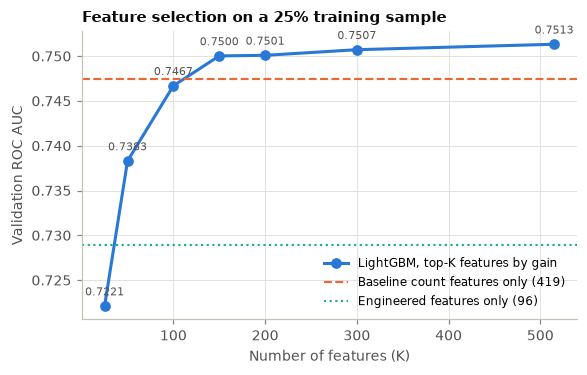

In [11]:
curve = exp2["topk_curve"]
k = [c["k"] for c in curve]
auc = [c["auc"] for c in curve]
fig, ax = plt.subplots(figsize=(5.8, 3.4))
ax.plot(k, auc, marker="o", ms=6, color=ps.SERIES[0], label="LightGBM, top-K features by gain")
ax.axhline(exp2["baseline_counts"]["auc"], color=ps.SERIES[1], lw=1.4, ls="--",
           label=f"Baseline count features only ({exp2['baseline_counts']['n_features']})")
ax.axhline(exp2["engineered_only"]["auc"], color=ps.SERIES[2], lw=1.4, ls=":",
           label=f"Engineered features only ({exp2['engineered_only']['n_features']})")
for x, y in zip(k, auc):
    ax.annotate(f"{y:.4f}", (x, y), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=7, color=ps.INK2)
ax.set_xlabel("Number of features (K)")
ax.set_ylabel("Validation ROC AUC")
ax.set_title("Feature selection on a 25% training sample")
ax.legend(loc="lower right")
show(fig, "feature_selection_curve.png")

The 96 engineered features alone are weaker than the 419 count features (validation AUC 0.729 against 0.748),
but the two groups together are better than either (0.751). The curve is almost flat from 150 features on
(0.7501 with 200 features against 0.7513 with all 515), so the top 200 features by gain are kept.

## 5. Experiment 3: model comparison

On the top-200 features the following models are trained on the full training sample: logistic regression
(standardised inputs, 25% sample), LightGBM with early stopping, and three CatBoost configurations on the GPU.
CatBoost pools are passed unquantized: a pre-quantized train pool combined with a raw eval pool broke GPU
training (AUC about 0.61). The best CatBoost by validation AUC becomes the final model.

In [12]:
LGB_PARAMS = {"objective": "binary", "learning_rate": 0.03, "num_leaves": 64, "max_depth": -1,
              "min_child_samples": 300, "feature_fraction": 0.5, "bagging_fraction": 0.8,
              "bagging_freq": 1, "reg_lambda": 5, "metric": "auc", "verbose": -1, "seed": 42, "n_jobs": -1}
CB_CONFIGS = {
    "cb_d6_lr05": dict(depth=6, learning_rate=0.05, l2_leaf_reg=3),
    "cb_d8_lr05": dict(depth=8, learning_rate=0.05, l2_leaf_reg=5),
    "cb_d8_lr06_bern": dict(depth=8, learning_rate=0.06, l2_leaf_reg=10, bootstrap_type="Bernoulli",
                            subsample=0.8, iterations=12000),
}

if RETRAIN:
    cols = imp.feature.head(K).tolist()
    with open(MODELS_DIR / "selected_features.json", "w") as f:
        json.dump(cols, f, indent=1)
else:
    cols = json.load(open(MODELS_DIR / "selected_features.json"))
print("selected features:", len(cols))

selected features: 200


In [13]:
def save_preds(name, p_va, p_te):
    np.save(MODELS_DIR / f"pred_valid_{name}.npy", p_va)
    np.save(MODELS_DIR / f"pred_oot_{name}.npy", p_te)


if RETRAIN:
    exp3 = {}
    Xtr, ytr, _ = load(TRAIN_PARTS, cols)
    Xva, _, _ = load(VALID_PARTS, cols)
    Xte, _, _ = load(OOT_PARTS, cols)

    # logistic regression on a 25% sample
    t0 = time.time()
    s = np.sort(np.random.default_rng(0).choice(len(ytr), len(ytr) // 4, replace=False))
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=300))
    lr.fit(Xtr[s], ytr[s])
    p_va, p_te = lr.predict_proba(Xva)[:, 1], lr.predict_proba(Xte)[:, 1]
    save_preds("logreg", p_va, p_te)
    joblib.dump(lr, MODELS_DIR / "logreg.joblib")
    exp3["logreg"] = {"valid": summary(yva, p_va), "oot": summary(yte, p_te), "train_time_s": time.time() - t0}

    # LightGBM
    t0 = time.time()
    dtr = lgb.Dataset(Xtr, label=ytr, feature_name=cols, free_raw_data=True)
    dva = lgb.Dataset(Xva, label=yva, reference=dtr)
    b = lgb.train(LGB_PARAMS, dtr, 5000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(200, verbose=False), lgb.log_evaluation(250)])
    p_va, p_te = b.predict(Xva, num_iteration=b.best_iteration), b.predict(Xte, num_iteration=b.best_iteration)
    b.save_model(str(MODELS_DIR / "lgb_tuned.txt"), num_iteration=b.best_iteration)
    save_preds("lgb_tuned", p_va, p_te)
    exp3["lgb_tuned"] = {"valid": summary(yva, p_va), "oot": summary(yte, p_te),
                         "best_iteration": b.best_iteration, "train_time_s": time.time() - t0}
    del dtr, dva, b

    # CatBoost on the GPU; the Pool keeps its own copy of the data, so the matrix is released
    ptr = Pool(Xtr, ytr, feature_names=cols)
    del Xtr
    gc.collect()
    pva = Pool(Xva, yva, feature_names=cols)
    for name, cfg in CB_CONFIGS.items():
        t0 = time.time()
        params = dict(iterations=6000, loss_function="Logloss", eval_metric="AUC",
                      task_type="GPU", devices="0", random_seed=42, border_count=254,
                      od_type="Iter", od_wait=300, use_best_model=True, verbose=500)
        params.update(cfg)
        m = CatBoostClassifier(**params)
        m.fit(ptr, eval_set=pva)
        p_va, p_te = m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1]
        m.save_model(str(MODELS_DIR / f"{name}.cbm"))
        save_preds(name, p_va, p_te)
        exp3[name] = {"valid": summary(yva, p_va), "oot": summary(yte, p_te), "params": cfg,
                      "best_iteration": int(m.get_best_iteration()), "train_time_s": time.time() - t0}
    del ptr, pva, Xva, Xte
    gc.collect()
else:
    exp3 = {k: v for k, v in read_json("exp3_models.json").items() if isinstance(v, dict)}
    X_cache = {}

    def oot_valid_matrix():
        if not X_cache:
            X_cache["va"] = load(VALID_PARTS, cols)[0]
            X_cache["te"] = load(OOT_PARTS, cols)[0]
        return X_cache["va"], X_cache["te"]

    def model_predictions(name):
        def predict():
            Xva, Xte = oot_valid_matrix()
            if name == "logreg":
                m = joblib.load(MODELS_DIR / "logreg.joblib")
                return m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1]
            if name == "lgb_tuned":
                b = lgb.Booster(model_file=str(MODELS_DIR / "lgb_tuned.txt"))
                return b.predict(Xva), b.predict(Xte)
            m = CatBoostClassifier()
            m.load_model(str(MODELS_DIR / f"{name}.cbm"))
            return m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1]
        return cached_predictions(name, predict)

    for name in ["logreg", "lgb_tuned", *CB_CONFIGS]:
        p_va, p_te = model_predictions(name)
        exp3[name] = dict(exp3.get(name, {}), valid=summary(yva, p_va), oot=summary(yte, p_te))
    X_cache.clear()
    gc.collect()

# simple blend of the best CatBoost and LightGBM
best_cb = max((k for k in exp3 if k.startswith("cb_")), key=lambda n: exp3[n]["valid"]["auc"])
p_va = 0.5 * np.load(MODELS_DIR / f"pred_valid_{best_cb}.npy") + 0.5 * np.load(MODELS_DIR / "pred_valid_lgb_tuned.npy")
p_te = 0.5 * np.load(MODELS_DIR / f"pred_oot_{best_cb}.npy") + 0.5 * np.load(MODELS_DIR / "pred_oot_lgb_tuned.npy")
save_preds("blend", p_va, p_te)
exp3["blend"] = {"valid": summary(yva, p_va), "oot": summary(yte, p_te), "members": [best_cb, "lgb_tuned"]}
if RETRAIN:
    write_json(dict(exp3, best_catboost=best_cb, k=K), "exp3_models.json")
print("best CatBoost by validation AUC:", best_cb)
assert best_cb == FINAL

pd.DataFrame({k: {"valid AUC": v["valid"]["auc"], "OOT AUC": v["oot"]["auc"], "OOT Gini": v["oot"]["gini"],
                  "OOT KS": v["oot"]["ks"], "OOT mean PD": v["oot"]["mean_pd"],
                  "train time, s": v.get("train_time_s")} for k, v in exp3.items()}).T.round(4)

best CatBoost by validation AUC: cb_d8_lr06_bern


,valid AUC,OOT AUC,OOT Gini,OOT KS,OOT mean PD,"train time, s"
logreg,0.7321,0.7213,0.4426,0.3301,0.0342,6.2225
lgb_tuned,0.7585,0.7433,0.4866,0.3562,0.0340,199.8771
cb_d6_lr05,0.7576,0.7428,0.4855,0.3568,0.0339,145.7630
cb_d8_lr05,0.7577,0.7429,0.4858,0.3577,0.0337,126.2331
cb_d8_lr06_bern,0.7585,0.7433,0.4866,0.3570,0.0337,122.4685
blend,0.7601,0.7449,0.4897,0.3591,0.0338,NaN


LightGBM and the final CatBoost reach the same OOT AUC (0.7433), both above the baseline (0.7356) and the
logistic regression (0.7213); the three CatBoost settings differ by less than 0.001, so the features matter much
more than the tuning. The blend adds only 0.0016 AUC, which does not justify keeping two models. CatBoost is
chosen for practical reasons: it trains quickly on the GPU, its symmetric trees predict fast in the application,
and it computes exact SHAP values, which the explanation page of the application needs.

## 6. Experiment 4: out-of-time validation, calibration and master scale

All checks below use the OOT sample. Discrimination is reported with 95% bootstrap intervals (200 resamples),
and the gain over the baseline is a paired bootstrap difference on the same resamples.

In [14]:
NAMES = {"lgb_baseline": "LightGBM baseline", "logreg": "Logistic regression",
         "lgb_tuned": "LightGBM (new features)", FINAL: "CatBoost (final)"}
preds_va = {k: np.load(MODELS_DIR / f"pred_valid_{k}.npy") for k in NAMES}
preds_te = {k: np.load(MODELS_DIR / f"pred_oot_{k}.npy") for k in NAMES}
exp4 = {"final_model": FINAL}

rng = np.random.default_rng(7)
boot_idx = [rng.integers(0, len(yte), len(yte)) for _ in range(200)]
disc, boots = {}, {}
for k, p in preds_te.items():
    boots[k] = np.array([roc_auc_score(yte[i], p[i]) for i in boot_idx])
    disc[k] = dict(summary(yte, p), auc_ci=[float(np.percentile(boots[k], 2.5)), float(np.percentile(boots[k], 97.5))])
diff = boots[FINAL] - boots["lgb_baseline"]
exp4["auc_gain_vs_baseline"] = {"mean": float(diff.mean()),
                                "ci": [float(np.percentile(diff, 2.5)), float(np.percentile(diff, 97.5))]}
exp4["discrimination_oot"] = disc
print("AUC gain vs baseline:", exp4["auc_gain_vs_baseline"])
pd.DataFrame(disc).T[["auc", "auc_ci", "gini", "ks", "pr_auc", "brier"]]

AUC gain vs baseline: {'mean': 0.007663775934218542, 'ci': [0.006137057598554227, 0.009124423827294385]}


,auc,auc_ci,gini,ks,pr_auc,brier
lgb_baseline,0.735622,"[0.7317821003487034, 0.7390240071296788]",0.471244,0.348523,0.08813,0.186989
logreg,0.721306,"[0.7172096279738678, 0.7255585220661428]",0.442611,0.330092,0.082422,0.03112
lgb_tuned,0.74329,"[0.7395333561362043, 0.7471577383903306]",0.486579,0.356164,0.094303,0.030817
cb_d8_lr06_bern,0.743277,"[0.739158891184585, 0.7470583088563826]",0.486554,0.357,0.094026,0.030841


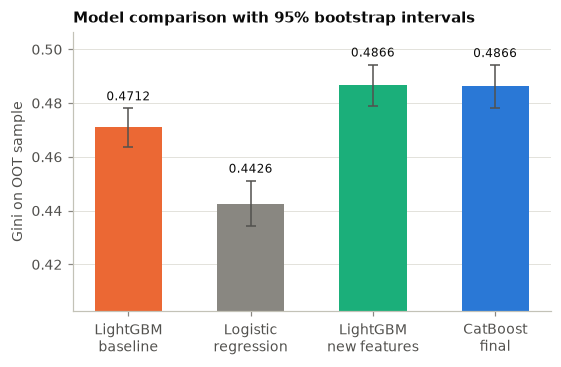

In [15]:
# Gini comparison with bootstrap intervals
names = {"lgb_baseline": "LightGBM\nbaseline", "logreg": "Logistic\nregression",
         "lgb_tuned": "LightGBM\nnew features", FINAL: "CatBoost\nfinal"}
keys = list(names)
vals = np.array([disc[k_]["gini"] for k_ in keys])
lo = np.array([2 * disc[k_]["auc_ci"][0] - 1 for k_ in keys])
hi = np.array([2 * disc[k_]["auc_ci"][1] - 1 for k_ in keys])
fig, ax = plt.subplots(figsize=(5.6, 3.3))
ax.bar(range(len(keys)), vals, color=[ps.SERIES[1], ps.MUTED, ps.SERIES[2], ps.SERIES[0]], width=0.55,
       yerr=[vals - lo, hi - vals], error_kw=dict(ecolor=ps.INK2, lw=1, capsize=3))
for i, v in enumerate(vals):
    ax.text(i, hi[i] + 0.003, f"{v:.4f}", ha="center", fontsize=8, color=ps.INK)
ax.set_xticks(range(len(keys)), [names[k_] for k_ in keys])
ax.set_ylim(vals.min() - 0.04, vals.max() + 0.02)
ax.set_ylabel("Gini on OOT sample")
ax.set_title("Model comparison with 95% bootstrap intervals")
ax.grid(axis="x", visible=False)
show(fig, "model_comparison.png")

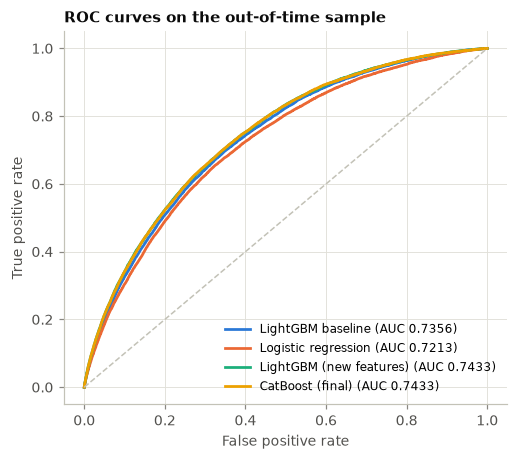

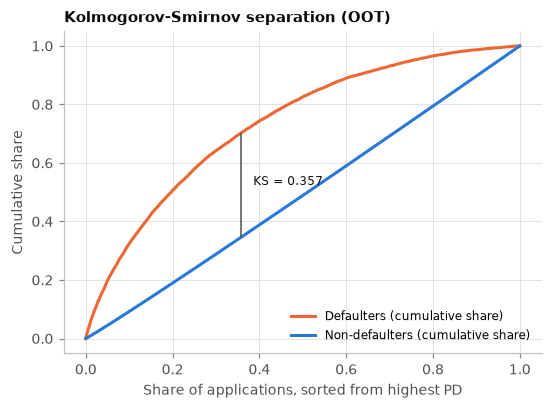

In [16]:
# ROC curves and KS separation
fig, ax = plt.subplots(figsize=(5.2, 4.4))
for i, (k, lbl) in enumerate(NAMES.items()):
    fpr, tpr, _ = roc_curve(yte, preds_te[k])
    ax.plot(fpr, tpr, color=ps.SERIES[i], lw=1.8, label=f"{lbl} (AUC {disc[k]['auc']:.4f})")
ax.plot([0, 1], [0, 1], color=ps.AXIS, lw=1, ls="--")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the out-of-time sample")
ax.legend(loc="lower right")
show(fig, "roc_oot.png")

p_final = preds_te[FINAL]
fig, ax = plt.subplots(figsize=(5.6, 3.8))
order = np.argsort(-p_final)
cum_bad = np.cumsum(yte[order]) / yte.sum()
cum_good = np.cumsum(1 - yte[order]) / (1 - yte).sum()
share = np.arange(1, len(yte) + 1) / len(yte)
ks_i = int(np.argmax(cum_bad - cum_good))
ax.plot(share, cum_bad, color=ps.SERIES[1], label="Defaulters (cumulative share)")
ax.plot(share, cum_good, color=ps.SERIES[0], label="Non-defaulters (cumulative share)")
ax.vlines(share[ks_i], cum_good[ks_i], cum_bad[ks_i], color=ps.INK2, lw=1)
ax.annotate(f"KS = {cum_bad[ks_i] - cum_good[ks_i]:.3f}", (share[ks_i], (cum_bad[ks_i] + cum_good[ks_i]) / 2),
            xytext=(8, 0), textcoords="offset points", color=ps.INK, fontsize=8)
ax.set_xlabel("Share of applications, sorted from highest PD")
ax.set_ylabel("Cumulative share")
ax.set_title("Kolmogorov-Smirnov separation (OOT)")
ax.legend(loc="lower right")
show(fig, "ks_oot.png")

### Calibration

The raw CatBoost PD is compared with two recalibrations fitted on the validation sample: Platt scaling (logistic
regression on the log-odds) and isotonic regression. Hosmer-Lemeshow uses 10 score deciles.

In [17]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


p_raw_va, p_raw = preds_va[FINAL], preds_te[FINAL]
platt = LogisticRegression(C=1e6).fit(logit(p_raw_va).reshape(-1, 1), yva)
p_platt = platt.predict_proba(logit(p_raw).reshape(-1, 1))[:, 1]
iso = IsotonicRegression(out_of_bounds="clip", y_min=1e-5, y_max=0.999).fit(p_raw_va, yva)
p_iso = iso.predict(p_raw)
calib = {}
for name, p in {"raw": p_raw, "platt": p_platt, "isotonic": p_iso}.items():
    hl, pv, _ = hosmer_lemeshow(yte, p)
    s = summary(yte, p)
    calib[name] = {"mean_pd": s["mean_pd"], "odr": s["default_rate"], "brier": s["brier"],
                   "logloss": s["logloss"], "auc": s["auc"], "hl_stat": hl, "hl_p": pv}
exp4["calibration"] = calib
exp4["platt"] = {"a": float(platt.coef_[0][0]), "b": float(platt.intercept_[0])}
pd.DataFrame(calib).T.round(5)

,mean_pd,odr,brier,logloss,auc,hl_stat,hl_p
raw,0.03370,0.03281,0.03084,0.13201,0.74328,159.39906,0.0
platt,0.03585,0.03281,0.03083,0.13201,0.74328,189.51061,0.0
isotonic,0.03587,0.03281,0.03080,0.13201,0.74318,212.42859,0.0


Recalibration changes the Brier score and log-loss only in the fifth decimal but moves the mean PD further from
the observed default rate (3.59% against 3.28%, raw 3.37%) and raises the Hosmer-Lemeshow statistic, so the raw
PD is kept. With 500,000 applications the
Hosmer-Lemeshow test rejects even small deviations; the decile plot below shows how small they are.

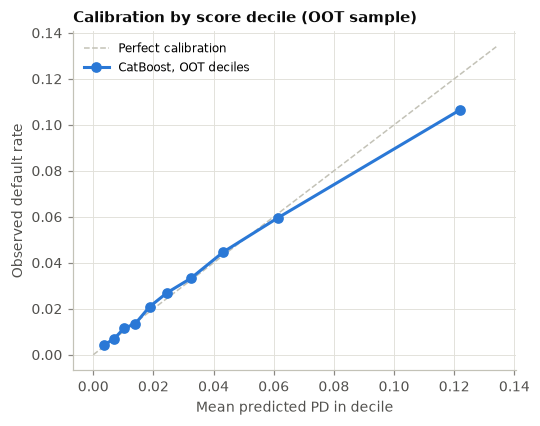

,obs,exp,n,mean_p,odr
g,,,,,
0,219,181.302694,50000,0.003626,0.00438
1,341,343.710986,50000,0.006874,0.00682
2,573,507.866373,50000,0.010157,0.01146
3,679,700.687784,50000,0.014014,0.01358
4,1044,936.002058,50000,0.018720,0.02088
5,1353,1231.369460,50000,0.024627,0.02706
6,1660,1619.871553,50000,0.032397,0.03320
7,2237,2164.333750,50000,0.043287,0.04474
8,2981,3073.374240,50000,0.061467,0.05962


In [18]:
_, _, dec = hosmer_lemeshow(yte, p_final)
dec["odr"] = dec.obs / dec.n
dec.to_csv(RESULTS_DIR / "calibration_deciles.csv")
fig, ax = plt.subplots(figsize=(5.2, 4))
ax.plot([0, dec.mean_p.max() * 1.1], [0, dec.mean_p.max() * 1.1], color=ps.AXIS, lw=1, ls="--", label="Perfect calibration")
ax.plot(dec.mean_p, dec.odr, marker="o", ms=6, color=ps.SERIES[0], label="CatBoost, OOT deciles")
ax.set_xlabel("Mean predicted PD in decile")
ax.set_ylabel("Observed default rate")
ax.set_title("Calibration by score decile (OOT sample)")
ax.legend(loc="upper left")
show(fig, "calibration_deciles.png")
dec

### Master scale

The PD is mapped to ten grades R1-R10 (`pd_scoring/risk.py`): R1-R5 are approved, R6-R7 go to manual review and
R8-R10 are declined. In each grade a one-sided binomial test checks whether the observed defaults exceed what
the mean PD of the grade allows at the 99% level ("red" = more defaults than expected).

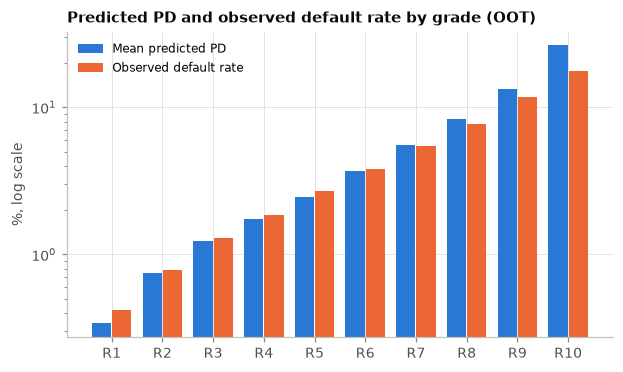

,grade,n,defaults,pd_mean,odr,p_value,critical_defaults_99,result,share
0,R1,44542,186,0.003437,0.004176,0.005359,183.0,red,0.089084
1,R2,78572,619,0.007444,0.007878,0.082297,642.0,green,0.157144
2,R3,63689,820,0.012400,0.012875,0.143434,855.0,green,0.127378
3,R4,50551,939,0.017409,0.018575,0.024257,949.0,green,0.101102
4,R5,74324,2016,0.024655,0.027124,0.000010,1931.0,red,0.148648
5,R6,70651,2701,0.036838,0.038230,0.025804,2720.0,green,0.141302
6,R7,59439,3254,0.055789,0.054745,0.868365,3447.0,green,0.118878
7,R8,30337,2350,0.082831,0.077463,0.999703,2625.0,green,0.060674
8,R9,24146,2858,0.132151,0.118363,1.000000,3314.0,green,0.048292
9,R10,3749,664,0.262956,0.177114,1.000000,1049.0,green,0.007498


In [19]:
bt = binomial_test_grades(yte, p_final, grade(p_final))
bt["share"] = bt.n / bt.n.sum()
bt = bt.set_index("grade").reindex(GRADE_NAMES).reset_index()
bt.to_csv(RESULTS_DIR / "master_scale_oot.csv", index=False)
exp4["master_scale"] = bt.fillna(0).to_dict(orient="records")
fig, ax = plt.subplots(figsize=(6.4, 3.6))
x = np.arange(len(GRADE_NAMES))
ax.bar(x - 0.2, bt.pd_mean * 100, width=0.38, color=ps.SERIES[0], label="Mean predicted PD")
ax.bar(x + 0.2, bt.odr * 100, width=0.38, color=ps.SERIES[1], label="Observed default rate")
ax.set_xticks(x, GRADE_NAMES)
ax.set_yscale("log")
ax.set_ylabel("%, log scale")
ax.set_title("Predicted PD and observed default rate by grade (OOT)")
ax.legend(loc="upper left")
show(fig, "master_scale.png")
bt

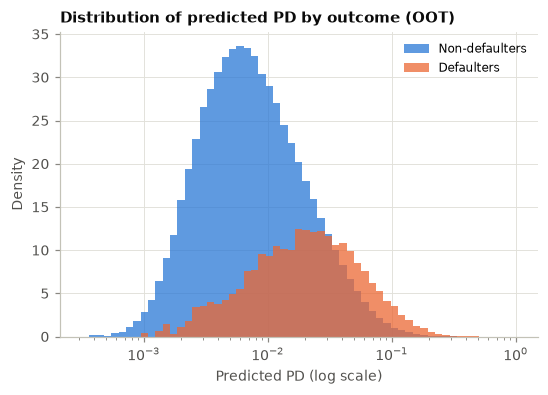

In [20]:
fig, ax = plt.subplots(figsize=(5.6, 3.6))
bins = np.logspace(-3.5, 0, 60)
ax.hist(p_final[yte == 0], bins=bins, density=True, alpha=0.75, color=ps.SERIES[0], label="Non-defaulters")
ax.hist(p_final[yte == 1], bins=bins, density=True, alpha=0.75, color=ps.SERIES[1], label="Defaulters")
ax.set_xscale("log")
ax.set_xlabel("Predicted PD (log scale)")
ax.set_ylabel("Density")
ax.set_title("Distribution of predicted PD by outcome (OOT)")
ax.legend()
show(fig, "pd_distribution.png")

### Stability over time

AUC and the default rate are computed for every block of 50,000 applications in the validation and OOT samples.
PSI compares the score distribution of validation and OOT; CSI does the same for the ten most important features
(training partitions 6-7 against OOT). Values below 0.1 are usually read as stable, 0.1-0.25 as a moderate shift.

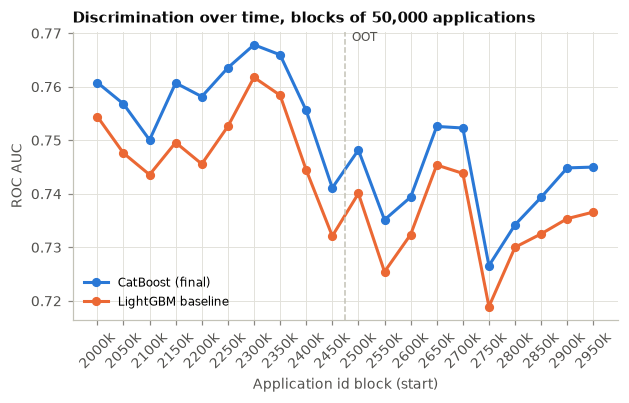

blocks where the final model beats the baseline: 20 of 20


In [21]:
blocks = []
for ids, y, p in ((ids_va, yva, preds_va), (ids_te, yte, preds_te)):
    b = ids // 50_000
    for blk in np.unique(b):
        m = b == blk
        blocks.append({"block": int(blk), "n": int(m.sum()), "dr": float(y[m].mean()),
                       "auc_final": float(roc_auc_score(y[m], p[FINAL][m])),
                       "auc_baseline": float(roc_auc_score(y[m], p["lgb_baseline"][m])),
                       "mean_pd": float(p[FINAL][m].mean())})
blocks = pd.DataFrame(blocks)
blocks.to_csv(RESULTS_DIR / "auc_by_block.csv", index=False)
exp4["auc_by_block"] = {"final_min": float(blocks.auc_final.min()), "final_max": float(blocks.auc_final.max()),
                        "final_std": float(blocks.auc_final.std()), "baseline_std": float(blocks.auc_baseline.std())}
fig, ax = plt.subplots(figsize=(6.4, 3.4))
lab = [f"{int(b) * 50}k" for b in blocks.block]
ax.plot(range(len(blocks)), blocks.auc_final, marker="o", ms=5, color=ps.SERIES[0], label="CatBoost (final)")
ax.plot(range(len(blocks)), blocks.auc_baseline, marker="o", ms=5, color=ps.SERIES[1], label="LightGBM baseline")
ax.axvline(9.5, color=ps.AXIS, lw=1, ls="--")
ax.text(9.6, ax.get_ylim()[1], " OOT", va="top", color=ps.INK2, fontsize=8)
ax.set_xticks(range(len(blocks)), lab, rotation=45)
ax.set_xlabel("Application id block (start)")
ax.set_ylabel("ROC AUC")
ax.set_title("Discrimination over time, blocks of 50,000 applications")
ax.legend(loc="lower left")
show(fig, "auc_by_block.png")
print("blocks where the final model beats the baseline:", int((blocks.auc_final > blocks.auc_baseline).sum()), "of", len(blocks))

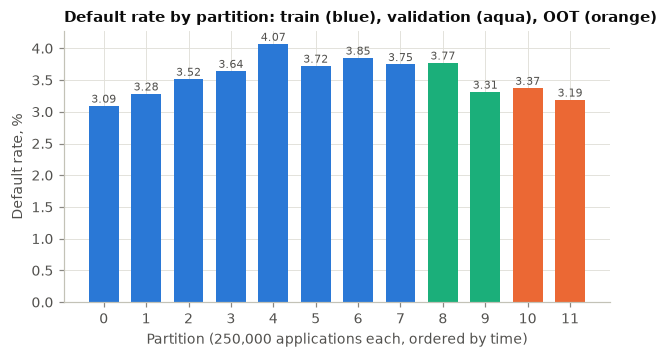

In [22]:
drp = tgt.groupby("part").flag.agg(["mean", "size"]).reset_index()
drp.to_csv(RESULTS_DIR / "default_rate_by_partition.csv", index=False)
fig, ax = plt.subplots(figsize=(6.4, 3.2))
colors = [ps.SERIES[0]] * 8 + [ps.SERIES[2]] * 2 + [ps.SERIES[1]] * 2
ax.bar(drp.part, drp["mean"] * 100, color=colors, width=0.7)
for i, v in enumerate(drp["mean"] * 100):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=7.5, color=ps.INK2)
ax.set_xticks(drp.part, [str(i) for i in drp.part])
ax.set_xlabel("Partition (250,000 applications each, ordered by time)")
ax.set_ylabel("Default rate, %")
ax.set_title("Default rate by partition: train (blue), validation (aqua), OOT (orange)")
show(fig, "default_rate_by_partition.png")

In [23]:
shap_imp_path = RESULTS_DIR / f"shap_importance_{FINAL}.csv"
top10 = pd.read_csv(shap_imp_path).feature.head(10).tolist() if shap_imp_path.exists() else cols[:10]
tr_f = load_frame(TRAIN_PARTS[-2:], top10)
te_f = load_frame(OOT_PARTS, top10)
exp4["csi_top_features"] = {c: psi(tr_f[c].to_numpy(), te_f[c].to_numpy()) for c in top10}
exp4["psi_score_valid_vs_oot"] = psi(preds_va[FINAL], preds_te[FINAL])
exp4["psi_score_valid_vs_oot_baseline"] = psi(preds_va["lgb_baseline"], preds_te["lgb_baseline"])
write_json(exp4, "exp4_validation.json")
del tr_f, te_f
print("PSI of the score (validation vs OOT):", round(exp4["psi_score_valid_vs_oot"], 4))
pd.Series(exp4["csi_top_features"], name="CSI").round(4)

PSI of the score (validation vs OOT): 0.0005


cnt__pre_util_3                       0.0036
cnt__pre_till_pclose_10               0.0063
cnt__pre_util_6                       0.0008
cnt__enc_loans_credit_type_0          0.0033
cnt__pre_loans_credit_cost_rate_11    0.1110
last__enc_loans_credit_type           0.0016
cnt__pre_loans_credit_cost_rate_9     0.0001
agg__is_zero_util_share               0.0060
pay__s1_last12_share                  0.0011
cnt__pre_util_18                      0.0014
Name: CSI, dtype: float64

## 7. Experiment 5: model interpretation with SHAP

Exact TreeSHAP values of the final CatBoost model (CatBoost `ShapValues`) are computed for a random sample of
20,000 OOT applicants. SHAP values are in log-odds: a positive value raises the PD of that applicant.

In [24]:
N_SHAP = 20_000
FAMILIES = [
    ("Payment history", ("enc_paym", "pay__")),
    ("Overdue counts and flags", ("pre_loans5", "pre_loans530", "pre_loans3060", "pre_loans6090", "pre_loans90",
                                  "is_zero_loans")),
    ("Utilisation and amounts", ("pre_util", "is_zero_util", "over2limit", "pre_loans_credit_limit",
                                 "pre_loans_outstanding", "pre_loans_next_pay_summ", "pre_loans_total_overdue",
                                 "pre_loans_max_overdue_sum")),
    ("Credit cost, type and status", ("pre_loans_credit_cost_rate", "enc_loans")),
    ("Terms, dates and history length", ("pre_since", "pre_pterm", "pre_fterm", "pre_till", "close_flag", "n_loans")),
]


def family(feature):
    for name, keys in FAMILIES:
        if any(k in feature for k in keys):
            return name
    return "Other"


model = CatBoostClassifier()
model.load_model(str(MODELS_DIR / f"{FINAL}.cbm"))
Xs, ys, ids_s = load(OOT_PARTS, cols, sample_frac=N_SHAP / 500_000, seed=11)
sv = model.get_feature_importance(Pool(Xs, ys, feature_names=cols), type="ShapValues")
base, sv = sv[0, -1], sv[:, :-1]
np.save(RESULTS_DIR / "shap_values_sample.npy", sv.astype(np.float32))

simp = pd.DataFrame({"feature": cols, "mean_abs_shap": np.abs(sv).mean(0)}).sort_values("mean_abs_shap", ascending=False)
simp["description"] = simp.feature.map(describe)
simp["share"] = simp.mean_abs_shap / simp.mean_abs_shap.sum()
simp.to_csv(RESULTS_DIR / f"shap_importance_{FINAL}.csv", index=False)
names_s = [describe(c) for c in cols]
simp.head(15)

,feature,mean_abs_shap,description,share
4,cnt__pre_util_3,0.162621,# products with utilisation (bin) = 3,0.037813
9,cnt__pre_till_pclose_10,0.130206,# products with days to planned close (bin) = 10,0.030276
6,cnt__pre_util_6,0.112029,# products with utilisation (bin) = 6,0.026050
10,cnt__enc_loans_credit_type_0,0.103080,# products with credit type = 0,0.023969
53,cnt__pre_loans_credit_cost_rate_11,0.081202,# products with full cost of credit (bin) = 11,0.018881
31,last__enc_loans_credit_type,0.066750,Latest product: credit type,0.015521
55,cnt__pre_loans_credit_cost_rate_9,0.063403,# products with full cost of credit (bin) = 9,0.014743
5,agg__is_zero_util_share,0.062475,Share of products: zero utilisation,0.014527
12,pay__s1_last12_share,0.060686,"Share of late (status 1) payments, last 12 months",0.014111
49,cnt__pre_util_18,0.060094,# products with utilisation (bin) = 18,0.013973


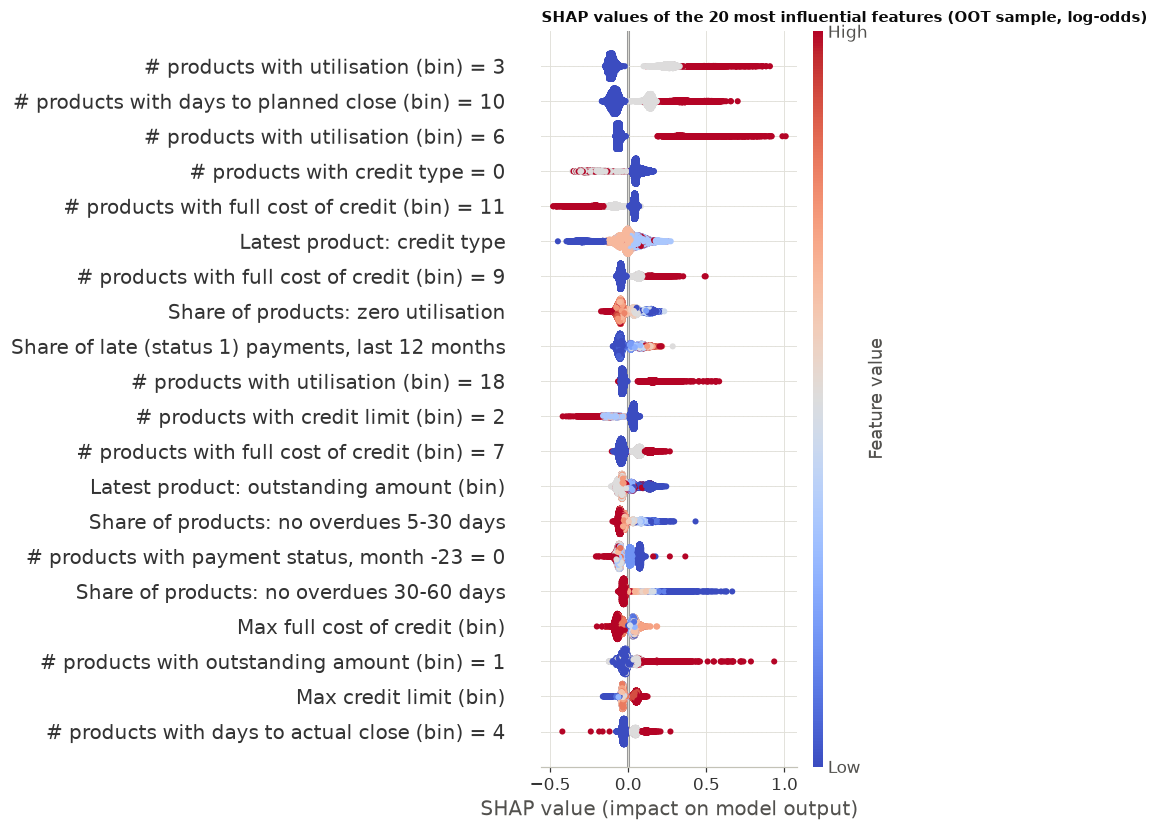

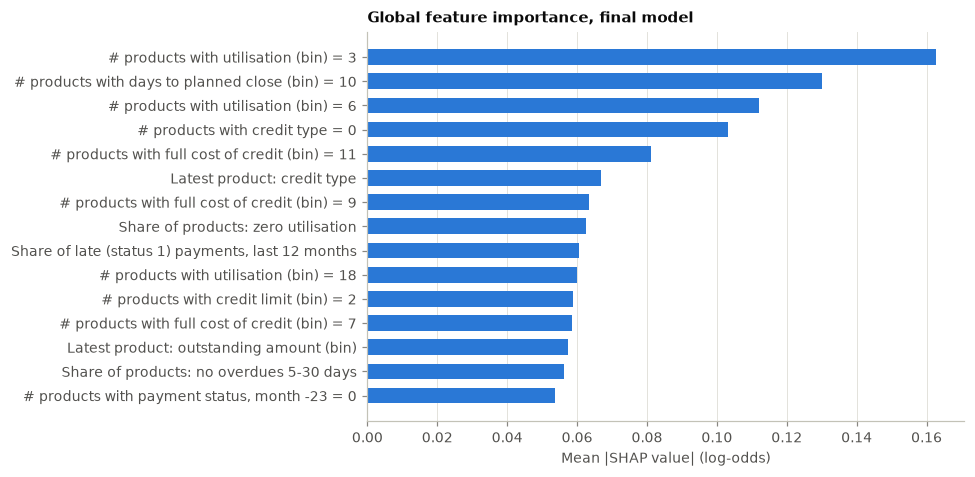

In [25]:
plt.figure()
shap.summary_plot(sv, pd.DataFrame(Xs, columns=names_s), max_display=20, show=False, plot_size=(8, 7.5),
                  cmap=plt.get_cmap("coolwarm"))
plt.title("SHAP values of the 20 most influential features (OOT sample, log-odds)", loc="left", fontsize=10)
plt.savefig(FIGURES_DIR / "shap_beeswarm.png", dpi=200, bbox_inches="tight")
plt.show()

top = simp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(top.description, top.mean_abs_shap, color=ps.SERIES[0], height=0.65)
ax.set_xlabel("Mean |SHAP value| (log-odds)")
ax.set_title("Global feature importance, final model")
ax.grid(axis="y", visible=False)
show(fig, "shap_bar.png")

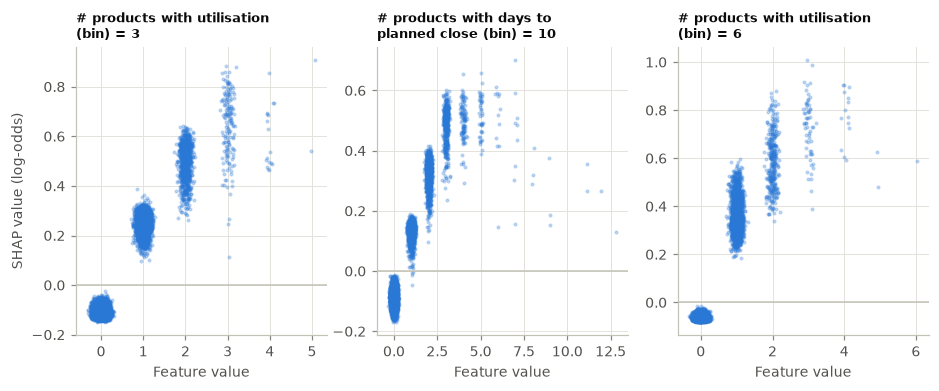

In [26]:
# dependence plots for the three strongest features
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, feat in zip(axes, simp.feature.head(3)):
    j = cols.index(feat)
    ax.scatter(Xs[:, j] + np.random.default_rng(0).normal(0, 0.08, len(Xs)), sv[:, j], s=3, alpha=0.25, color=ps.SERIES[0])
    ax.axhline(0, color=ps.AXIS, lw=1)
    ax.set_title(textwrap.fill(describe(feat), 30), fontsize=8.5)
    ax.set_xlabel("Feature value")
axes[0].set_ylabel("SHAP value (log-odds)")
show(fig, "shap_dependence.png")

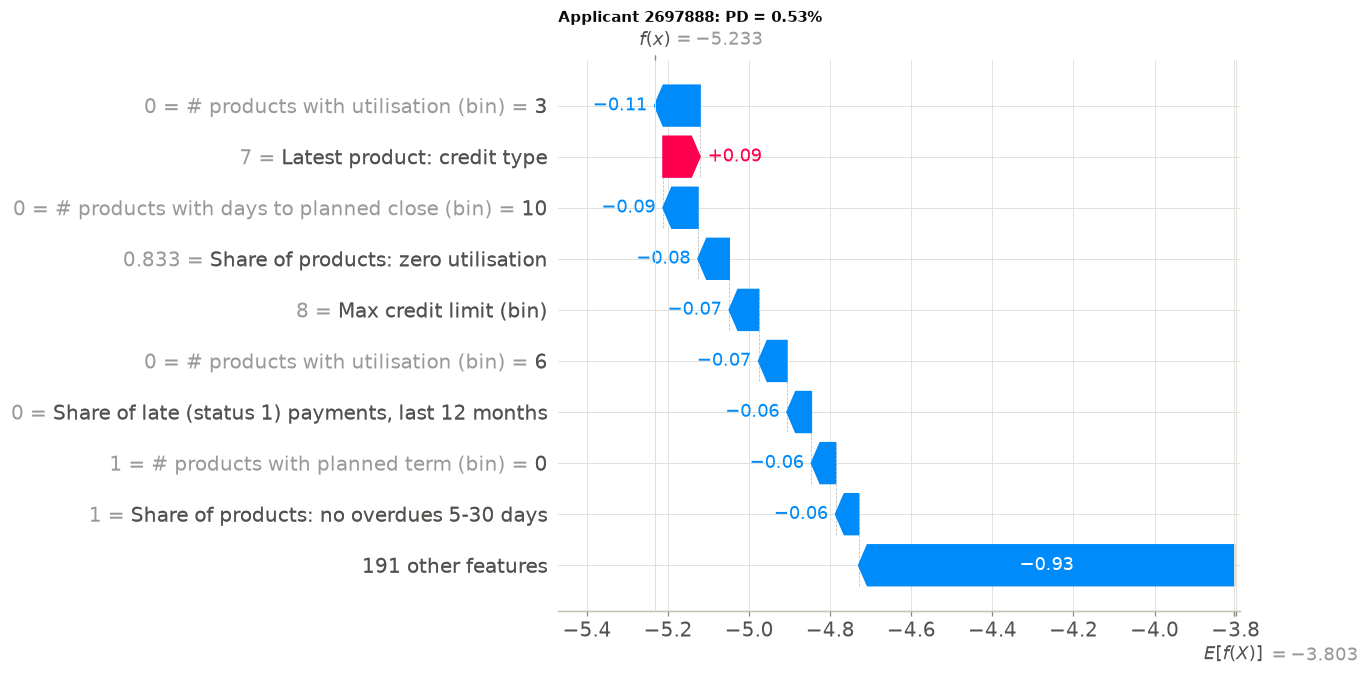

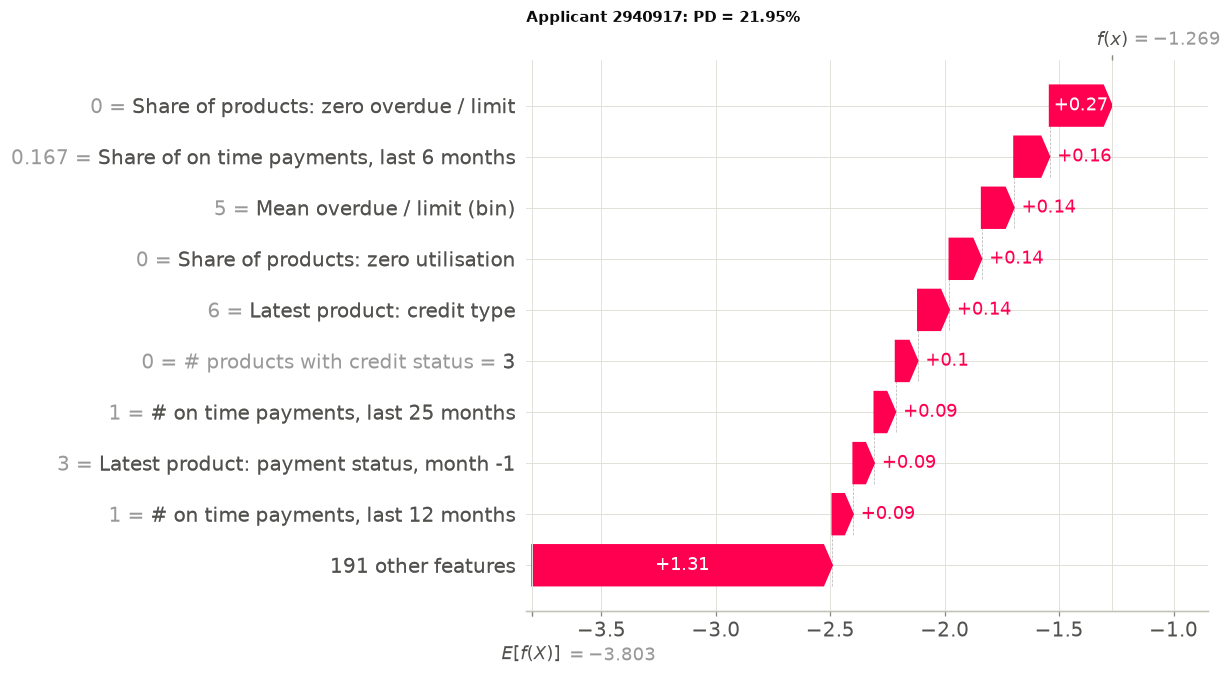

{'low': {'id': 2697888, 'pd': 0.005306665279181181, 'default': 0},
 'high': {'id': 2940917, 'pd': 0.21946284146059328, 'default': 0}}

In [27]:
# local explanations of one low-risk and one high-risk applicant
p_s = 1 / (1 + np.exp(-(base + sv.sum(1))))
picks = {"low": int(np.argmin(np.abs(p_s - np.quantile(p_s, 0.10)))),
         "high": int(np.argmin(np.abs(p_s - np.quantile(p_s, 0.995))))}
local = {}
for tag, i in picks.items():
    exp_i = shap.Explanation(values=sv[i], base_values=base, data=Xs[i], feature_names=names_s)
    plt.figure()
    shap.plots.waterfall(exp_i, max_display=10, show=False)
    plt.title(f"Applicant {ids_s[i]}: PD = {p_s[i]:.2%}", loc="left", fontsize=10)
    plt.savefig(FIGURES_DIR / f"shap_waterfall_{tag}.png", dpi=200, bbox_inches="tight")
    plt.show()
    local[tag] = {"id": int(ids_s[i]), "pd": float(p_s[i]), "default": int(ys[i])}
local

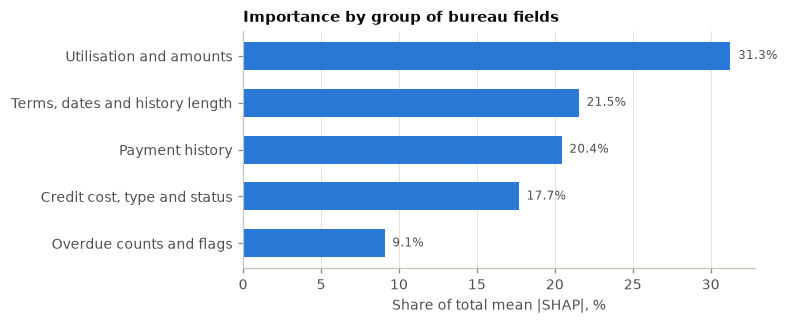

feature
Utilisation and amounts            0.3126
Terms, dates and history length    0.2154
Payment history                    0.2043
Credit cost, type and status       0.1769
Overdue counts and flags           0.0908
Name: share, dtype: float64

In [28]:
fam = simp.groupby(simp.feature.map(family)).share.sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(fam.index[::-1], fam.values[::-1] * 100, color=ps.SERIES[0], height=0.6)
for i, v in enumerate(fam.values[::-1] * 100):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8, color=ps.INK2)
ax.set_xlabel("Share of total mean |SHAP|, %")
ax.set_title("Importance by group of bureau fields")
ax.grid(axis="y", visible=False)
show(fig, "shap_families.png")
write_json({"base_value": float(base), "base_pd": float(1 / (1 + np.exp(-base))), "local": local,
            "families": fam.to_dict(),
            "by_type": simp.groupby(simp.feature.str.split("__").str[0]).share.sum().to_dict(),
            "top20": simp.head(20).to_dict(orient="records")}, "exp5_shap.json")
del Xs
fam.round(4)

## 8. Experiment 6: stress testing

* **Part A, macro scenarios (top-down).** The Vasicek one-factor model gives the PD conditional on a bad state of
  the economy: PD_stress = Φ((Φ⁻¹(PD) + √ρ·Φ⁻¹(q)) / √(1 − ρ)), where q is the severity (0.95 = a 1-in-20 year
  downturn) and ρ is the Basel correlation for other retail exposures. Expected loss EL = PD · LGD · EAD with
  EAD = 1, so the loss rate is a share of exposure.
* **Part B, bottom-up shocks.** Payment records of 40,000 OOT applicants are changed (for example, the latest
  payment of a share of on-time loans becomes late) and the applicants are re-scored by the model.
* **Part C, reverse stress test.** The severity at which the portfolio loss rate reaches a 5% limit, and the share
  of on-time loans that must turn late to double the mean PD.

In [29]:
APPROVE_CUTOFF = 0.03  # approve grades R1-R5
LOSS_LIMIT = 0.05      # reverse stress: loss rate the lender can absorb
SCENARIOS = [  # name, quantile of the systematic factor, LGD
    ("Baseline", None, LGD_BASE),
    ("Mild downturn (1-in-5)", 0.80, LGD_BASE),
    ("Adverse (1-in-20)", 0.95, LGD_BASE),
    ("Severe (1-in-100)", 0.99, LGD_DOWNTURN),
    ("Extreme (Basel 1-in-1000)", 0.999, LGD_DOWNTURN),
]


def portfolio_stats(p, lgd):
    g = grade(p)
    return {"mean_pd": float(p.mean()), "median_pd": float(np.median(p)),
            "el_rate": float((p * lgd).mean()),
            "approval_rate": float((p < APPROVE_CUTOFF).mean()),
            "share_decline_grades": float(np.isin(g, GRADE_NAMES[7:]).mean()),
            "grade_mix": {k: float((g == k).mean()) for k in GRADE_NAMES}}


exp6 = {}
pd_oot = preds_te[FINAL]

# correlation implied by the variation of the default rate over time
blk = tgt.assign(block=tgt.id // 50_000).groupby("block").flag.agg(["mean", "size"])
rho_hat, tv, sampv = estimate_rho_from_default_rates(blk["mean"], blk["size"])
exp6["rho_estimate"] = {"rho": rho_hat, "total_var": tv, "sampling_var": sampv, "n_blocks": int(len(blk)),
                        "dr_min": float(blk["mean"].min()), "dr_max": float(blk["mean"].max())}

scen, stressed = [], {}
for name, q, lgd in SCENARIOS:
    p = pd_oot if q is None else vasicek_conditional_pd(pd_oot, q)
    stressed[name] = p
    row = {"scenario": name, "q": q, "lgd": lgd, **portfolio_stats(p, lgd)}
    row["capital_k_mean"] = float(irb_capital(pd_oot, lgd).mean()) if q is None else None
    scen.append(row)
for name, q, lgd in SCENARIOS[1:]:
    p = vasicek_conditional_pd(pd_oot, q, rho=rho_hat)
    scen.append({"scenario": name + " [empirical rho]", "q": q, "lgd": lgd, **portfolio_stats(p, lgd)})
exp6["macro_scenarios"] = scen
exp6["observed_oot_default_rate"] = float(yte.mean())
exp6["irb_capital_mean_k"] = float(irb_capital(pd_oot, LGD_BASE).mean())
print("empirical rho:", round(rho_hat, 4), "| mean IRB capital K:", round(exp6["irb_capital_mean_k"], 4))
pd.DataFrame(scen).drop(columns="grade_mix").round(4)

empirical rho: 0.0021 | mean IRB capital K: 0.0595


,scenario,q,lgd,mean_pd,median_pd,el_rate,approval_rate,share_decline_grades,capital_k_mean
0,Baseline,NaN,0.6,0.0337,0.0214,0.0202,0.6234,0.1165,0.0595
1,Mild downturn (1-in-5),0.800,0.6,0.0454,0.0316,0.0272,0.4796,0.1928,NaN
2,Adverse (1-in-20),0.950,0.6,0.0673,0.0545,0.0404,0.2376,0.3659,NaN
3,Severe (1-in-100),0.990,0.7,0.0934,0.0828,0.0654,0.0710,0.6086,NaN
4,Extreme (Basel 1-in-1000),0.999,0.7,0.1328,0.1262,0.0930,0.0046,0.8764,NaN
5,Mild downturn (1-in-5) [empirical rho],0.800,0.6,0.0363,0.0234,0.0218,0.5932,0.1327,NaN
6,Adverse (1-in-20) [empirical rho],0.950,0.6,0.0390,0.0255,0.0234,0.5621,0.1499,NaN
7,Severe (1-in-100) [empirical rho],0.990,0.7,0.0414,0.0274,0.0290,0.5354,0.1659,NaN
8,Extreme (Basel 1-in-1000) [empirical rho],0.999,0.7,0.0443,0.0296,0.0310,0.5047,0.1850,NaN


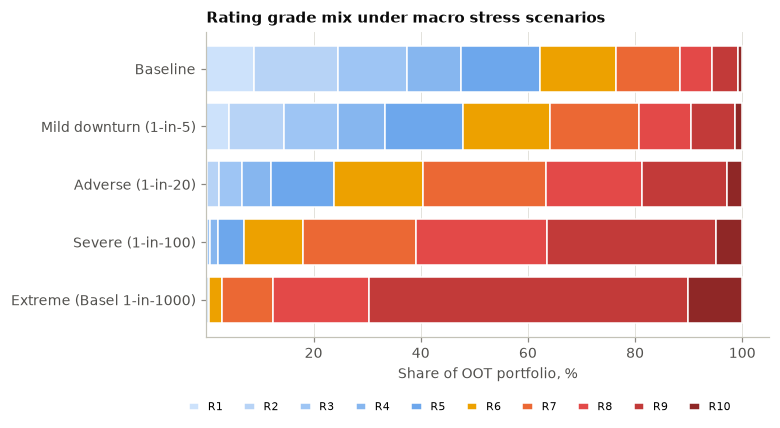

In [30]:
fig, ax = plt.subplots(figsize=(6.6, 3.6))
snames = [s[0] for s in SCENARIOS]
mix = np.array([[portfolio_stats(stressed[n], 0.6)["grade_mix"][g] for g in GRADE_NAMES] for n in snames])
left = np.zeros(len(snames))
ramp = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#eda100", "#eb6834", "#e34948", "#c23a39", "#8f2726"]
for j, gname in enumerate(GRADE_NAMES):
    ax.barh(snames, mix[:, j] * 100, left=left, color=ramp[j], edgecolor="white", linewidth=1, label=gname)
    left += mix[:, j] * 100
ax.invert_yaxis()
ax.set_xlabel("Share of OOT portfolio, %")
ax.set_title("Rating grade mix under macro stress scenarios")
ax.legend(ncol=10, loc="upper center", bbox_to_anchor=(0.45, -0.18), fontsize=7, handlelength=1)
ax.grid(axis="y", visible=False)
show(fig, "stress_grade_mix.png")

In [31]:
# Part B: bottom-up payment shocks on a 40,000-application OOT sample
rng = np.random.default_rng(5)
sloans = pd.concat([pq.read_table(raw_part_path(i)).to_pandas() for i in (10, 11)], ignore_index=True)
sample_ids = rng.choice(sloans.id.unique(), 40_000, replace=False)
sloans = sloans[sloans.id.isin(sample_ids)].astype("int32").reset_index(drop=True)
y_s = tgt.set_index("id").loc[np.sort(sample_ids), "flag"].to_numpy()


def score(lo):
    f = build_features(lo, spec)
    return model.predict_proba(f[cols].to_numpy(np.float32))[:, 1]


p0 = score(sloans)
on_time = sloans.enc_paym_0.to_numpy() == 0
u = rng.random(len(sloans))
shocks = []
for f in (0.05, 0.10, 0.25, 0.50):
    lo = sloans.copy()
    hit = on_time & (u < f)
    lo.loc[hit, "enc_paym_0"] = 1
    lo.loc[hit, "is_zero_loans5"] = 0
    shocks.append({"shock": f"Latest payment late on {int(f * 100)}% of on-time loans", "share": f,
                   **portfolio_stats(score(lo), LGD_BASE),
                   "affected_applicants": float(lo.loc[hit, "id"].nunique() / 40_000)})
# escalation: existing recent lateness deepens and spreads to the 5-30 day bucket
lo = sloans.copy()
late = lo.enc_paym_0.isin([1, 2]).to_numpy()
lo.loc[late, "enc_paym_0"] = 2
lo.loc[late, "enc_paym_1"] = np.where(lo.loc[late, "enc_paym_1"] == 0, 1, lo.loc[late, "enc_paym_1"])
lo.loc[late, "is_zero_loans530"] = 0
shocks.append({"shock": "Existing late loans escalate (status 2, 5-30 day overdue)", "share": None,
               **portfolio_stats(score(lo), LGD_BASE),
               "affected_applicants": float(lo.loc[late, "id"].nunique() / 40_000)})
# combined severe shock
lo = sloans.copy()
hit = on_time & (u < 0.25)
lo.loc[hit, "enc_paym_0"] = 1
lo.loc[hit, "is_zero_loans5"] = 0
lo.loc[late, "enc_paym_0"] = 2
lo.loc[late, "is_zero_loans530"] = 0
p_comb = score(lo)
shocks.append({"shock": "Combined: 25% new late + escalation", "share": None,
               **portfolio_stats(p_comb, LGD_DOWNTURN), "affected_applicants": None})
exp6["bottom_up"] = {"sample": 40_000, "observed_dr": float(y_s.mean()),
                     "base": portfolio_stats(p0, LGD_BASE), "shocks": shocks}
pd.DataFrame([dict(shock="No shock", **portfolio_stats(p0, LGD_BASE))] + shocks).drop(columns="grade_mix").round(4)

,shock,mean_pd,median_pd,el_rate,approval_rate,share_decline_grades,share,affected_applicants
0,No shock,0.0337,0.0214,0.0202,0.6240,0.1165,NaN,NaN
1,Latest payment late on 5% of on-time loans,0.0368,0.0240,0.0221,0.5844,0.1357,0.05,0.3332
2,Latest payment late on 10% of on-time loans,0.0397,0.0265,0.0238,0.5482,0.1536,0.10,0.5291
3,Latest payment late on 25% of on-time loans,0.0469,0.0325,0.0281,0.4661,0.2015,0.25,0.7896
4,Latest payment late on 50% of on-time loans,0.0566,0.0405,0.0340,0.3681,0.2663,0.50,0.9230
5,"Existing late loans escalate (status 2, 5-30 d...",0.0338,0.0213,0.0203,0.6252,0.1170,NaN,0.2024
6,Combined: 25% new late + escalation,0.0468,0.0325,0.0328,0.4670,0.2014,NaN,NaN


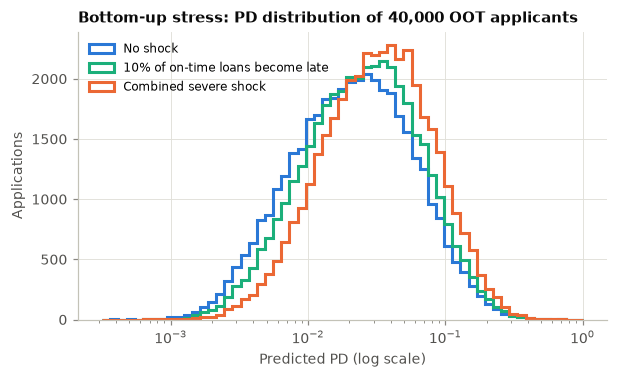

In [32]:
fig, ax = plt.subplots(figsize=(6.2, 3.4))
bins = np.logspace(-3.5, 0, 60)
ax.hist(p0, bins=bins, histtype="step", lw=2, color=ps.SERIES[0], label="No shock")
ax.hist(score(sloans.assign(enc_paym_0=np.where(on_time & (u < 0.10), 1, sloans.enc_paym_0))), bins=bins,
        histtype="step", lw=2, color=ps.SERIES[2], label="10% of on-time loans become late")
ax.hist(p_comb, bins=bins, histtype="step", lw=2, color=ps.SERIES[1], label="Combined severe shock")
ax.set_xscale("log")
ax.set_xlabel("Predicted PD (log scale)")
ax.set_ylabel("Applications")
ax.set_title("Bottom-up stress: PD distribution of 40,000 OOT applicants")
ax.legend(loc="upper left")
show(fig, "stress_bottom_up.png")

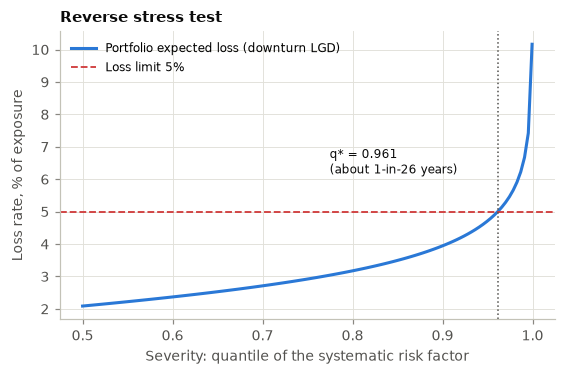

{'loss_limit': 0.05,
 'q_star': 0.9613054631361977,
 'return_period_years': 25.84344150492916,
 'pd_mean_at_q_star': 0.07142857142857142,
 'bottom_up_target_mean_pd': 0.06732696859881068,
 'bottom_up_curve': {'0.0': 0.03366348429940534,
  '0.1': 0.039697303502269056,
  '0.25': 0.046862182687790827,
  '0.5': 0.056634276437239624,
  '0.75': 0.06862677222761852,
  '1.0': 0.07988199043662364},
 'share_late_to_double_pd': 0.7229038131109744}

In [33]:
# Part C: reverse stress tests
def el_at(q):
    return float((vasicek_conditional_pd(pd_oot, q) * LGD_DOWNTURN).mean())


q_star = brentq(lambda q: el_at(q) - LOSS_LIMIT, 0.5, 0.99999)
qs = np.linspace(0.5, 0.9995, 120)
els = [el_at(q) for q in qs]


def mean_pd_at(f):
    lo = sloans.copy()
    hit = on_time & (u < f)
    lo.loc[hit, "enc_paym_0"] = 1
    lo.loc[hit, "is_zero_loans5"] = 0
    return float(score(lo).mean())


target = 2 * float(p0.mean())
fs = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0]
mp = [float(p0.mean())] + [mean_pd_at(f) for f in fs[1:]]
f_star = float(np.interp(target, mp, fs)) if max(mp) >= target else None
exp6["reverse"] = {"loss_limit": LOSS_LIMIT, "q_star": float(q_star), "return_period_years": float(1 / (1 - q_star)),
                   "pd_mean_at_q_star": float(vasicek_conditional_pd(pd_oot, q_star).mean()),
                   "bottom_up_target_mean_pd": target, "bottom_up_curve": dict(zip(map(str, fs), mp)),
                   "share_late_to_double_pd": f_star}
write_json(exp6, "exp6_stress.json")

fig, ax = plt.subplots(figsize=(5.8, 3.4))
ax.plot(qs, np.array(els) * 100, color=ps.SERIES[0], label="Portfolio expected loss (downturn LGD)")
ax.axhline(LOSS_LIMIT * 100, color=ps.CRITICAL, lw=1.2, ls="--", label=f"Loss limit {LOSS_LIMIT:.0%}")
ax.axvline(q_star, color=ps.INK2, lw=1, ls=":")
ax.annotate(f"q* = {q_star:.3f}\n(about 1-in-{1 / (1 - q_star):.0f} years)", (q_star, LOSS_LIMIT * 100),
            xytext=(-110, 25), textcoords="offset points", fontsize=8, color=ps.INK)
ax.set_xlabel("Severity: quantile of the systematic risk factor")
ax.set_ylabel("Loss rate, % of exposure")
ax.set_title("Reverse stress test")
ax.legend(loc="upper left")
show(fig, "stress_reverse.png")
exp6["reverse"]

## 9. Files for the web application

The Streamlit app (`streamlit run app/app.py`) uses the final model, the feature list and a few small files in
`artifacts/app/`: the most frequent value of every field (the default form values), a sample portfolio of 3,000
OOT applicants for batch scoring and the stress lab, and three example applicants. They are already in the
repository; set `UPDATE_APP_ASSETS = True` to rebuild them. `TAKE_SCREENSHOTS = True` captures the app
screenshots used in Section 4.8 of the report (needs Chrome and the app running on port 8599).

In [34]:
ASSETS = ROOT / "artifacts" / "app"
if UPDATE_APP_ASSETS:
    ASSETS.mkdir(parents=True, exist_ok=True)
    loans11 = pq.read_table(raw_part_path(11)).to_pandas()
    json.dump({c: int(loans11[c].mode()[0]) for c in loans11.columns if c not in ("id", "rn")},
              open(ASSETS / "defaults.json", "w"), indent=1)
    app_ids = np.sort(np.random.default_rng(3).choice(loans11.id.unique(), 3000, replace=False))
    sample = loans11[loans11.id.isin(app_ids)].reset_index(drop=True)
    sample.to_parquet(ASSETS / "sample_loans.parquet", index=False)
    tgt[tgt.id.isin(app_ids)][["id", "flag"]].to_parquet(ASSETS / "sample_target.parquet", index=False)
    json.dump({"name": FINAL, "oot": exp4["discrimination_oot"][FINAL]}, open(ASSETS / "final_model.json", "w"), indent=1)

    sys.path.insert(0, str(ROOT / "app"))
    from scoring import Scorer
    sc = Scorer().score(sample).merge(tgt[["id", "flag"]], on="id")
    q = sc.pd.quantile([0.10, 0.5, 0.97]).to_numpy()
    examples = {tag: int(sc.iloc[(sc.pd - v).abs().argmin()].id) for tag, v in zip(("low", "medium", "high"), q)}
    json.dump(examples, open(ASSETS / "examples.json", "w"), indent=1)

print(sorted(p.name for p in ASSETS.iterdir()))
print(json.load(open(ASSETS / "final_model.json"))["name"])

['defaults.json', 'examples.json', 'final_model.json', 'sample_loans.parquet', 'sample_target.parquet']
cb_d8_lr06_bern


In [35]:
if TAKE_SCREENSHOTS:
    from selenium import webdriver
    from selenium.webdriver.common.by import By
    from selenium.webdriver.common.keys import Keys

    URL = "http://localhost:8599"

    def wait_idle(drv, extra=2.5, timeout=60):
        t0 = time.time()
        while time.time() - t0 < timeout:
            if not drv.find_elements(By.CSS_SELECTOR, '[data-testid="stStatusWidget"]'):
                break
            time.sleep(0.5)
        time.sleep(extra)

    def shot(drv, name):
        h = drv.execute_script(
            "const m=document.querySelector('section.main, [data-testid=\"stMain\"]');"
            "return Math.max(document.body.scrollHeight, m ? m.scrollHeight : 0);")
        drv.set_window_size(1400, int(min(max(h, 900), 4200)))
        time.sleep(1.5)
        drv.save_screenshot(str(FIGURES_DIR / name))

    def goto(drv, label):
        for el in drv.find_elements(By.CSS_SELECTOR, '[data-testid="stSidebar"] label'):
            if el.text.strip() == label:
                el.click()
                wait_idle(drv, 4)
                return
        raise RuntimeError(label)

    opt = webdriver.ChromeOptions()
    for a in ("--headless=new", "--window-size=1400,1000", "--hide-scrollbars", "--force-device-scale-factor=1"):
        opt.add_argument(a)
    drv = webdriver.Chrome(options=opt)
    try:
        drv.get(URL)
        time.sleep(6)
        wait_idle(drv, 6)
        shot(drv, "app_applicant.png")
        inp = drv.find_elements(By.CSS_SELECTOR, '[data-testid="stSelectbox"] input')[0]
        inp.click()
        time.sleep(0.8)
        inp.send_keys("high risk")
        time.sleep(0.8)
        inp.send_keys(Keys.ENTER)
        wait_idle(drv, 6)
        drv.find_element(By.TAG_NAME, "h3").click()
        time.sleep(1)
        shot(drv, "app_applicant_high.png")
        for page, fname in (("Batch scoring", "app_batch.png"), ("Stress lab", "app_stress.png"),
                            ("Model card", "app_model_card.png")):
            drv.set_window_size(1400, 1000)
            goto(drv, page)
            shot(drv, fname)
    finally:
        drv.quit()

## 10. Summary of key results

In [36]:
fin = disc[FINAL]
ms = bt.set_index("grade")
macro = {s["scenario"]: s["mean_pd"] for s in exp6["macro_scenarios"]}
summary_rows = {
    "Baseline AUC, random split": exp1["random_split_auc"],
    "Baseline AUC, OOT": disc["lgb_baseline"]["auc"],
    "Final CatBoost AUC, validation": exp3[FINAL]["valid"]["auc"],
    "Final CatBoost AUC, OOT": fin["auc"],
    "Final CatBoost Gini, OOT": fin["gini"],
    "Final CatBoost KS, OOT": fin["ks"],
    "AUC gain vs baseline (paired bootstrap mean)": exp4["auc_gain_vs_baseline"]["mean"],
    "Mean predicted PD, OOT": fin["mean_pd"],
    "Observed default rate, OOT": fin["default_rate"],
    "PSI of the score, validation vs OOT": exp4["psi_score_valid_vs_oot"],
    "Max CSI of top-10 features": max(exp4["csi_top_features"].values()),
    "Approval rate (grades R1-R5)": exp6["macro_scenarios"][0]["approval_rate"],
    "Mean PD, 1-in-20 scenario": macro["Adverse (1-in-20)"],
    "Mean PD, 1-in-100 scenario": macro["Severe (1-in-100)"],
    "Mean PD, 1-in-1000 scenario": macro["Extreme (Basel 1-in-1000)"],
    "Reverse stress q* (loss rate = 5%)": exp6["reverse"]["q_star"],
    "Mean IRB capital K": exp6["irb_capital_mean_k"],
    "Share of on-time loans turning late that doubles the PD": exp6["reverse"]["share_late_to_double_pd"],
}
pd.Series(summary_rows, name="value").round(4).to_frame()

,value
"Baseline AUC, random split",0.7586
"Baseline AUC, OOT",0.7356
"Final CatBoost AUC, validation",0.7585
"Final CatBoost AUC, OOT",0.7433
"Final CatBoost Gini, OOT",0.4866
"Final CatBoost KS, OOT",0.3570
AUC gain vs baseline (paired bootstrap mean),0.0077
"Mean predicted PD, OOT",0.0337
"Observed default rate, OOT",0.0328
"PSI of the score, validation vs OOT",0.0005
